# So sánh và Trực quan hoá Standard PSO thông qua các Tiêu chí Cơ bản
**Tác giả:** Nghiên cứu Tối ưu hóa Bầy đàn (PSO)  
**Mục tiêu:** Thiết lập khung đánh giá hệ thống để phân tích, đo lường và trực quan hóa các tiêu chí cơ bản của thuật toán **Standard PSO (PSO tiêu chuẩn)**, bao gồm:
1. **Tốc độ & Chất lượng Hội tụ (Convergence Speed & Solution Quality)**: Giá trị hàm mục tiêu tốt nhất (Gbest) và trung bình bầy đàn qua từng thế hệ.
2. **Cân bằng Khám phá - Khai thác & Độ đa dạng Quần thể (Exploration vs. Exploitation & Swarm Diversity)**: Độ tản mát của bầy đàn so với trọng tâm theo thời gian.
3. **Động học Vận tốc & Kẹp vận tốc (Velocity Dynamics & Clamping)**: Mức độ kích hoạt vận tốc, kiểm tra hiện tượng bùng nổ vận tốc hoặc tê liệt tìm kiếm.
4. **Độ nhạy Tham số (Parameter Sensitivity Analysis)**: Khảo sát tác động của Trọng số quán tính $w$, Hệ số gia tốc cá nhân/xã hội $(c_1, c_2)$, và Quy mô bầy đàn $N$.
5. **Độ ổn định & Bền vững (Robustness & Statistical Stability)**: Phân phối kết quả qua nhiều lần khởi tạo ngẫu nhiên độc lập (multi-run seeds).
6. **Quỹ đạo Hạt & Phân bố Không gian Tìm kiếm (Particle Trajectories & Search Space Distribution)**: Trực quan hóa 2D với tỉ lệ vuông và màu pastel nhẹ nhàng.
7. **Thực nghiệm Ứng dụng & Biểu đồ Phân tán Thực tế:** Nạp dữ liệu từ 2 bộ dữ liệu thực tế **Bank Marketing** và **Forest Covertype**, trực quan hóa biểu đồ phân tán hạt (Particle Distribution Scatter Plot) với tỉ lệ vuông 1:1.


In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import joblib

# =========================================================================
# TỰ ĐỘNG XÁC ĐỊNH VÀ THIẾT LẬP ĐƯỜNG DẪN DỰ ÁN (ROBUST PATH RESOLUTION)
# Đảm bảo chạy mượt mà dù kernel mở từ VS Code, JupyterLab hay Terminal
# =========================================================================
cwd = os.path.abspath(os.getcwd())

candidate_comparing_dirs = [
    # Khi mở từ thư mục notebooks:
    os.path.abspath(os.path.join(cwd, '..')),
    # Khi mở trực tiếp từ thư mục comparing:
    cwd,
    # Khi mở từ workspace root d:\Code\JupyterNotebook:
    os.path.abspath(os.path.join(cwd, 'comparing')),
    # Đường dẫn tuyệt đối chuẩn của workspace:
    r'd:\Code\JupyterNotebook\comparing'
]

COMPARING_DIR = None
for d in candidate_comparing_dirs:
    if os.path.exists(os.path.join(d, 'src', 'standard_pso.py')):
        COMPARING_DIR = d
        break

if COMPARING_DIR is None:
    COMPARING_DIR = r'd:\Code\JupyterNotebook\comparing'

WORKSPACE_ROOT = os.path.dirname(COMPARING_DIR)

# Thêm COMPARING_DIR vào sys.path để import các module src.*
if COMPARING_DIR not in sys.path:
    sys.path.insert(0, COMPARING_DIR)

# Đồng bộ cwd về thư mục notebooks để các file tương đối luôn đúng
notebooks_dir = os.path.join(COMPARING_DIR, 'notebooks')
if os.path.exists(notebooks_dir):
    try:
        os.chdir(notebooks_dir)
    except Exception:
        pass

from src.benchmarks import BENCHMARK_SUITE, sphere, rastrigin, rosenbrock
from src.standard_pso import StandardPSO
from src.metrics import compute_run_metrics, aggregate_experiment_metrics
from src.visualization import (
    plot_convergence_and_diversity,
    plot_particle_trajectories_2d,
    plot_parameter_sensitivity,
    plot_robustness_boxplots,
    plot_real_datasets_scatter,
    PALETTE,
    setup_plot_style
)

setup_plot_style()
print(f"✅ Khai báo thư viện và kết nối module src thành công!")
print(f"   -> Comparing Root: {COMPARING_DIR}")
print(f"   -> Workspace Root: {WORKSPACE_ROOT}")


✅ Khai báo thư viện và kết nối module src thành công!
   -> Comparing Root: d:\Code\JupyterNotebook\comparing
   -> Workspace Root: d:\Code\JupyterNotebook


---
## 1. Giới thiệu Hàm Mục tiêu Thử nghiệm (Benchmark Objective Functions)
Để đánh giá toàn diện các tiêu chí của Standard PSO một cách khách quan, chúng ta sử dụng các hàm tối ưu hóa chuẩn:
* **Sphere Function (Đơn đỉnh - Unimodal):** Mặt phẳng cong parabol tròn xoay, kiểm tra khả năng hội tụ nhanh và khai thác cục bộ (Local Exploitation).
* **Rastrigin Function (Đa đỉnh - Highly Multimodal):** Chứa vô số cực tiểu địa phương (local minima bẫy), kiểm tra khả năng nhảy thoát bẫy và khám phá toàn cục (Global Exploration).
* **Rosenbrock Function (Thung lũng cong hẹp):** Kiểm tra khả năng bám theo độ cong uốn lượn phức tạp.


In [2]:
benchmark_df = pd.DataFrame([
    {
        'Benchmark': name,
        'Loại hình': info['type'],
        'Miền giá trị [LB, UB]': f"[{info['bounds'][0]}, {info['bounds'][1]}]",
        'Cực trị lý thuyết f*': info['optimum'],
        'Ý nghĩa đánh giá tiêu chí': info['description']
    }
    for name, info in BENCHMARK_SUITE.items()
])
benchmark_df


,Benchmark,Loại hình,"Miền giá trị [LB, UB]",Cực trị lý thuyết f*,Ý nghĩa đánh giá tiêu chí
0,Sphere,Unimodal (Kiểm tra tốc độ khai thác - Exploita...,"[-5.12, 5.12]",0.0,"Mặt nón lồi hoàn hảo, đánh giá khả năng hội tụ..."
1,Rastrigin,Multimodal (Kiểm tra khả năng thoát cực tiểu đ...,"[-5.12, 5.12]",0.0,Bề mặt lồi lõm với vô số bẫy cực tiểu địa phươ...
2,Rosenbrock,Valley (Kiểm tra điều hướng trong thung lũng d...,"[-5.0, 10.0]",0.0,"Đáy thung lũng cong hẹp, kiểm tra khả năng bám..."


---
## 2. Tiêu chí 1 & 2: Tốc độ Hội tụ (Convergence) và Độ đa dạng Bầy đàn (Swarm Diversity)
* **Độ đa dạng quần thể (Swarm Diversity):** 
  $$\text{Diversity}(t) = \frac{1}{N} \sum_{i=1}^{N} \| X_i(t) - \bar{X}(t) \|_2$$
  Khi $t$ tăng, độ đa dạng giảm dần phản ánh quá trình chuyển từ giai đoạn **Khám phá (Exploration)** sang **Khai thác (Exploitation)**. Nếu độ đa dạng giảm về 0 quá sớm khi nghiệm chưa tối ưu, bầy đàn đã rơi vào bẫy hội tụ sớm (**Premature Convergence**).
* **Động học Vận tốc (Average Velocity Magnitude):**
  $$\bar{V}(t) = \frac{1}{N} \sum_{i=1}^N \| V_i(t) \|_2$$


In [3]:
# Chạy Standard PSO trên hàm Rastrigin (Bài toán khó, nhiều cực tiểu địa phương)
bench_rastrigin = BENCHMARK_SUITE['Rastrigin']
pso_rastrigin = StandardPSO(
    fitness_func=bench_rastrigin['func'],
    dim=2,
    bounds=bench_rastrigin['bounds'],
    n_particles=25,
    max_iter=40,
    w=0.7,
    c1=1.5,
    c2=1.5,
    random_seed=42
)

result_rastrigin = pso_rastrigin.optimize(verbose=True)
metrics_rastrigin = compute_run_metrics(result_rastrigin, optimum=bench_rastrigin['optimum'])

# Hiển thị bảng chỉ số tiêu chí
pd.DataFrame([metrics_rastrigin]).T.rename(columns={0: 'Giá trị đo lường'})


Iter  10/40 | Gbest: 3.035093e-01 | Diversity: 0.9305 | Avg Vel: 1.0414
Iter  20/40 | Gbest: 1.871540e-03 | Diversity: 0.5902 | Avg Vel: 0.7672
Iter  30/40 | Gbest: 8.470744e-04 | Diversity: 0.4708 | Avg Vel: 0.3741
Iter  40/40 | Gbest: 2.973301e-05 | Diversity: 0.2905 | Avg Vel: 0.3595


,Giá trị đo lường
Final_Value,0.000030
Absolute_Error,0.000030
Convergence_Iter,26.000000
Initial_Diversity,3.906532
Final_Diversity,0.290491
Diversity_Reduction_Pct,92.563978
Avg_Velocity_Mean,0.799922
Final_Velocity,0.359461
Runtime_Sec,0.001998


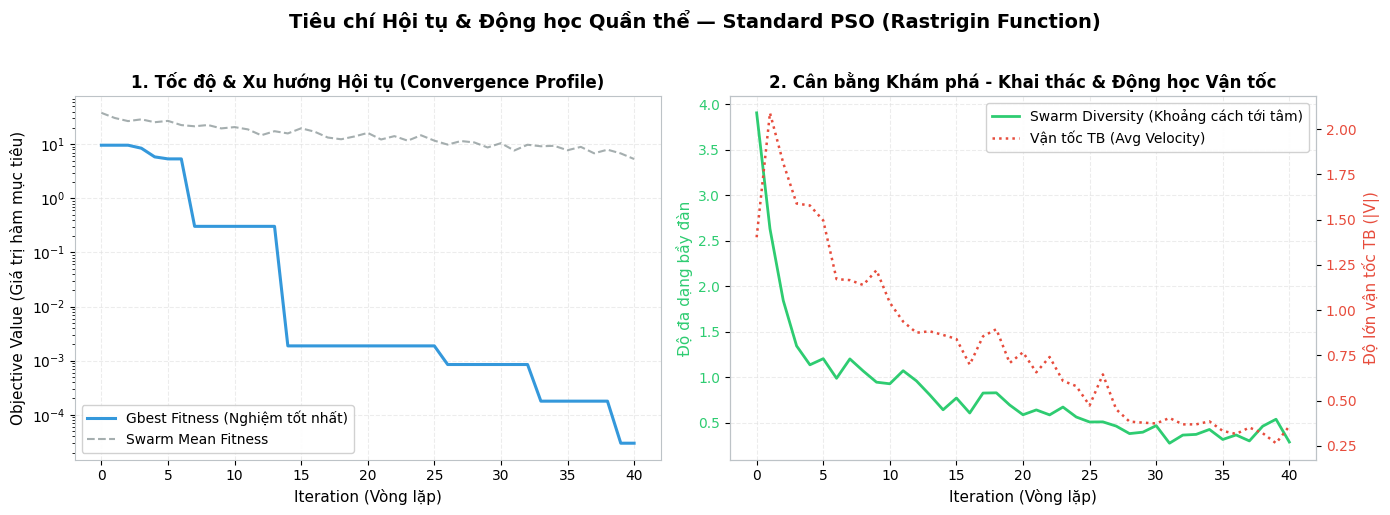

In [4]:
# Trực quan hoá Tiêu chí Hội tụ và Động học Quần thể
fig_conv = plot_convergence_and_diversity(result_rastrigin, func_name='Rastrigin')
plt.show()


---
## 3. Tiêu chí 3: Quỹ đạo Hạt & Phân bố Không gian Tìm kiếm (Particle Trajectories 2D)
Biểu đồ phân tán và quỹ đạo hạt 2D với **tỉ lệ khung hình vuông (Square Aspect Ratio 1:1)**, sử dụng bảng màu pastel dịu mắt:
* **Hạt xanh pastel (t=0):** Vị trí khởi tạo ngẫu nhiên đều khắp không gian tìm kiếm.
* **Đường nét đứt xám nhạt:** Quỹ đạo di chuyển của từng hạt qua các vòng lặp.
* **Hạt đỏ pastel (t=T):** Vị trí kết thúc của các hạt khi bầy đàn hội tụ.
* **Ngôi sao vàng:** Vị trí nghiệm tốt nhất toàn cục ($G_{best}$).


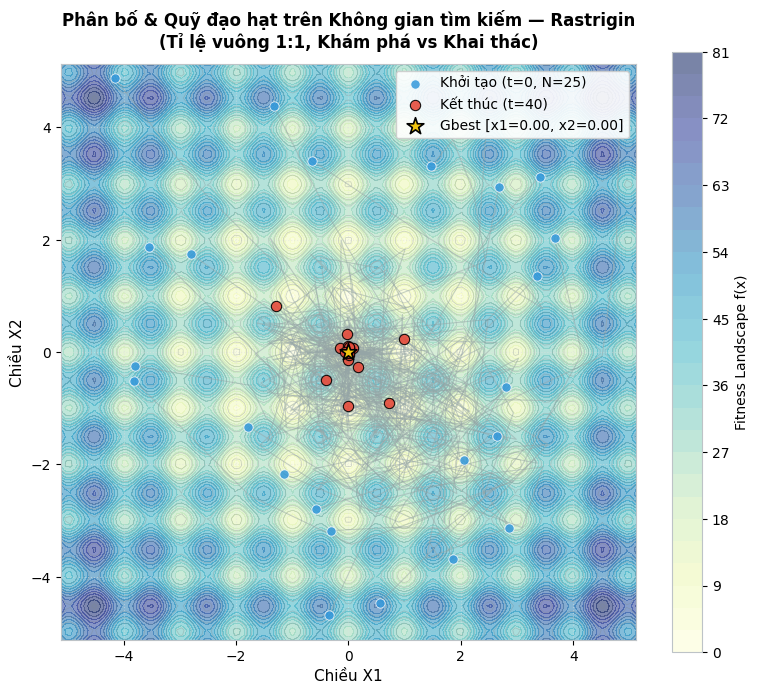

In [5]:
# Vẽ biểu đồ quỹ đạo 2D tỉ lệ vuông với đường đồng mức
fig_traj = plot_particle_trajectories_2d(
    result_rastrigin, 
    func=bench_rastrigin['func'], 
    bounds=bench_rastrigin['bounds'], 
    func_name='Rastrigin'
)
plt.show()


---
## 4. Kiểm tra trên Hàm Đơn đỉnh (Sphere Function - Thuần Khai thác)
Hàm Sphere kiểm tra xem thuật toán có đạt tốc độ hội tụ nhanh về điểm cực tiểu toàn cục $f(0,0)=0$ khi không bị cản trở bởi các cực tiểu địa phương.


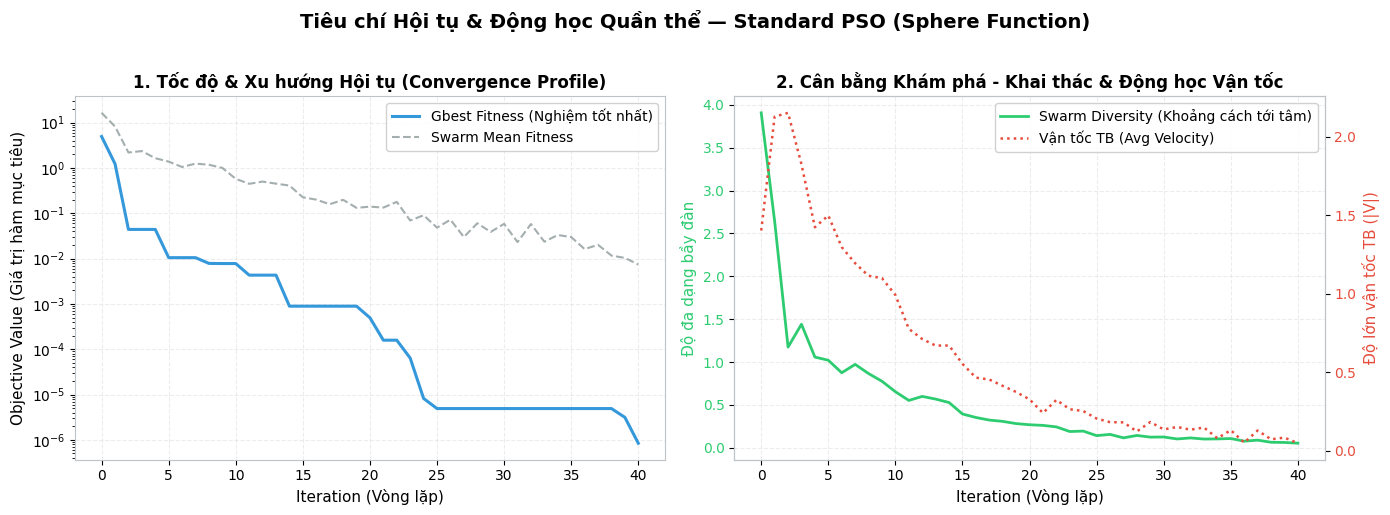

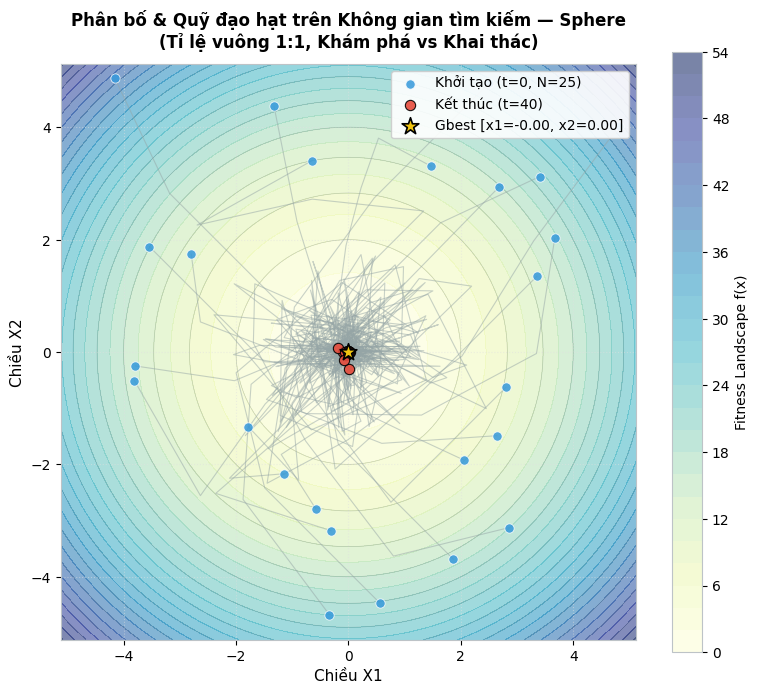

In [6]:
bench_sphere = BENCHMARK_SUITE['Sphere']
pso_sphere = StandardPSO(
    fitness_func=bench_sphere['func'],
    dim=2,
    bounds=bench_sphere['bounds'],
    n_particles=25,
    max_iter=40,
    w=0.7,
    c1=1.5,
    c2=1.5,
    random_seed=42
)
result_sphere = pso_sphere.optimize(verbose=False)

fig_sphere_conv = plot_convergence_and_diversity(result_sphere, func_name='Sphere')
plt.show()

fig_sphere_traj = plot_particle_trajectories_2d(
    result_sphere, 
    func=bench_sphere['func'], 
    bounds=bench_sphere['bounds'], 
    func_name='Sphere'
)
plt.show()


---
## 5. Tiêu chí 4: Phân tích Độ nhạy Tham số (Parameter Sensitivity Analysis)

### 5.1. Ảnh hưởng của Trọng số Quán tính ($w$)
* **$w = 0.9$ (Lớn):** Duy trì quán tính vận tốc cao, thúc đẩy **Khám phá toàn cục (Global Exploration)**, bầy đàn giữ độ đa dạng lâu hơn nhưng hội tụ chậm về cuối.
* **$w = 0.4$ (Nhỏ):** Triệt tiêu quán tính nhanh, thúc đẩy **Khai thác cục bộ (Local Exploitation)**, hội tụ rất nhanh ở giai đoạn đầu nhưng dễ sa lầy vào cực tiểu địa phương.
* **$w = 0.7$ (Trung bình):** Thiết lập chuẩn mực cân bằng giữa khám phá và khai thác.


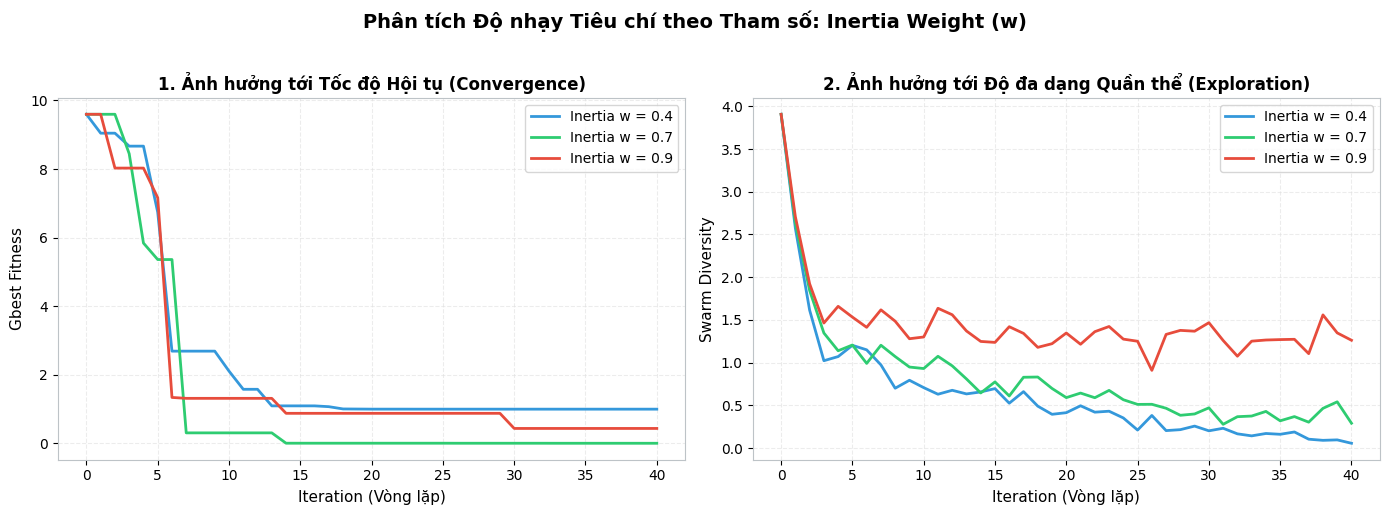

In [7]:
w_values = [0.4, 0.7, 0.9]
results_w = {}

for w_val in w_values:
    opt = StandardPSO(
        fitness_func=bench_rastrigin['func'],
        dim=2,
        bounds=bench_rastrigin['bounds'],
        n_particles=25,
        max_iter=40,
        w=w_val,
        c1=1.5,
        c2=1.5,
        random_seed=42
    )
    results_w[f"Inertia w = {w_val}"] = opt.optimize()

fig_w = plot_parameter_sensitivity(results_w, param_name="Inertia Weight (w)")
plt.show()


### 5.2. Ảnh hưởng của Hệ số Gia tốc Cá nhân ($c_1$) vs Xã hội ($c_2$)
* **$c_1 > c_2$ ($c_1=2.0, c_2=0.5$ - Cá nhân vượt trội):** Các hạt tự tin vào kinh nghiệm bản thân ($P_{best}$), chuyển động phân tán rộng, khám phá tốt nhưng khó đồng thuận hội tụ.
* **$c_1 < c_2$ ($c_1=0.5, c_2=2.0$ - Xã hội vượt trội):** Các hạt bị kéo mạnh về nghiệm tốt nhất toàn cục ($G_{best}$), tốc độ co cụm bầy đàn rất nhanh, tiềm ẩn nguy cơ hội tụ sớm.
* **$c_1 = c_2 = 1.5$ (Cân bằng):** Cân bằng giữa niềm tin cá nhân và học hỏi từ bầy đàn.


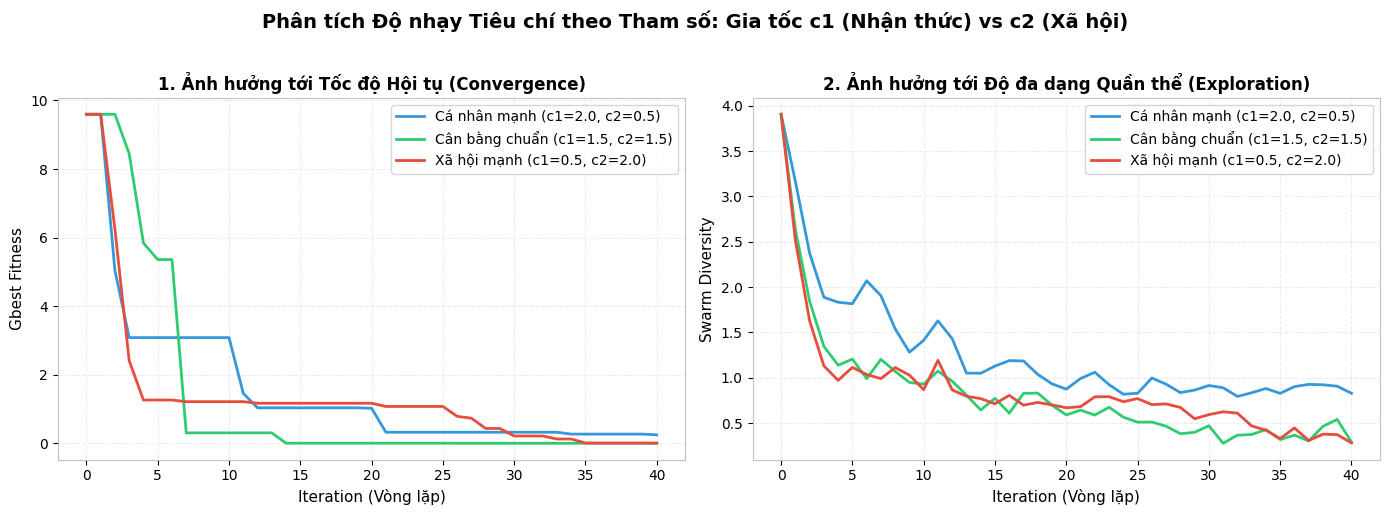

In [8]:
c_configs = {
    "Cá nhân mạnh (c1=2.0, c2=0.5)": (2.0, 0.5),
    "Cân bằng chuẩn (c1=1.5, c2=1.5)": (1.5, 1.5),
    "Xã hội mạnh (c1=0.5, c2=2.0)": (0.5, 2.0)
}
results_c = {}

for label, (c1_val, c2_val) in c_configs.items():
    opt = StandardPSO(
        fitness_func=bench_rastrigin['func'],
        dim=2,
        bounds=bench_rastrigin['bounds'],
        n_particles=25,
        max_iter=40,
        w=0.7,
        c1=c1_val,
        c2=c2_val,
        random_seed=42
    )
    results_c[label] = opt.optimize()

fig_c = plot_parameter_sensitivity(results_c, param_name="Gia tốc c1 (Nhận thức) vs c2 (Xã hội)")
plt.show()


### 5.3. Ảnh hưởng của Quy mô Bầy đàn ($N$ - Swarm Size)
Quy mô bầy đàn thể hiện sự đánh đổi giữa **Chi phí tính toán** và **Khả năng bao phủ không gian tìm kiếm**:
* $N=10$: Tính toán nhanh nhưng độ phủ thấp, dễ bỏ sót vùng nghiệm hứa hẹn.
* $N=25$: Cân bằng tốt giữa chi phí và độ phủ.
* $N=50$: Độ bao phủ không gian rất cao, tăng xác suất tìm thấy cực tiểu toàn cục.


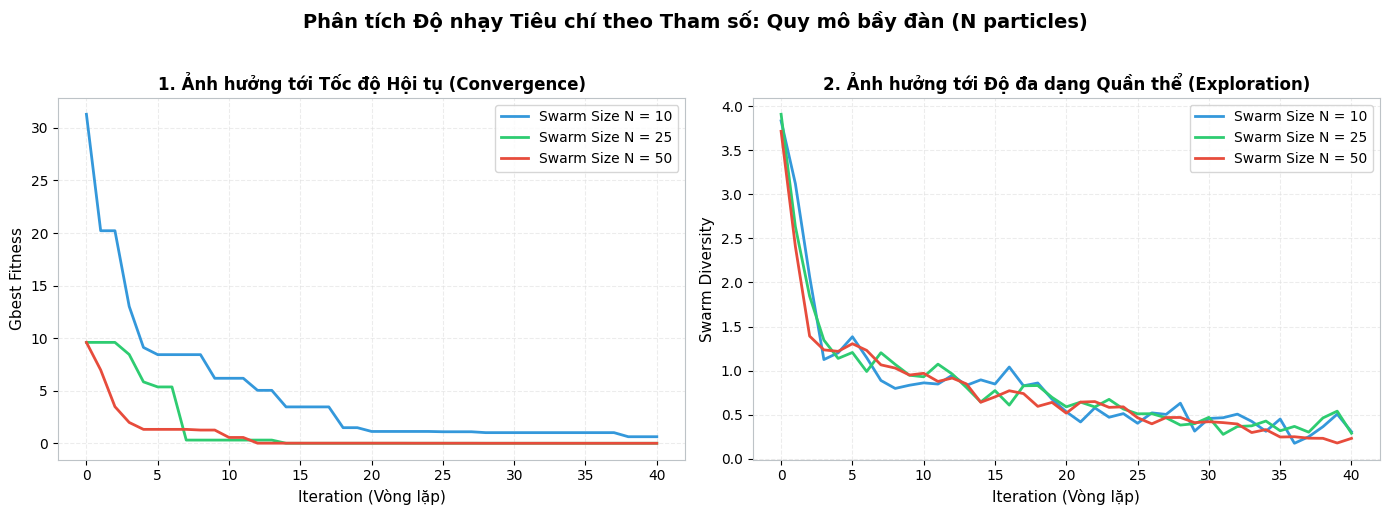

In [9]:
n_sizes = [10, 25, 50]
results_n = {}

for n_p in n_sizes:
    opt = StandardPSO(
        fitness_func=bench_rastrigin['func'],
        dim=2,
        bounds=bench_rastrigin['bounds'],
        n_particles=n_p,
        max_iter=40,
        w=0.7,
        c1=1.5,
        c2=1.5,
        random_seed=42
    )
    results_n[f"Swarm Size N = {n_p}"] = opt.optimize()

fig_n = plot_parameter_sensitivity(results_n, param_name="Quy mô bầy đàn (N particles)")
plt.show()


---
## 6. Tiêu chí 5: Độ ổn định & Độ bền vững Thống kê (Statistical Robustness across Runs)
Vì PSO là thuật toán ngẫu nhiên (Stochastic Metaheuristic), việc đánh giá trên 1 lần chạy đơn lẻ có thể bị chi phối bởi may mắn ngẫu nhiên. Chúng ta tiến hành thực nghiệm trên **20 random seeds độc lập** để đo lường độ phân tán (Boxplot), giá trị trung bình (Mean), và độ lệch chuẩn (Standard Deviation).


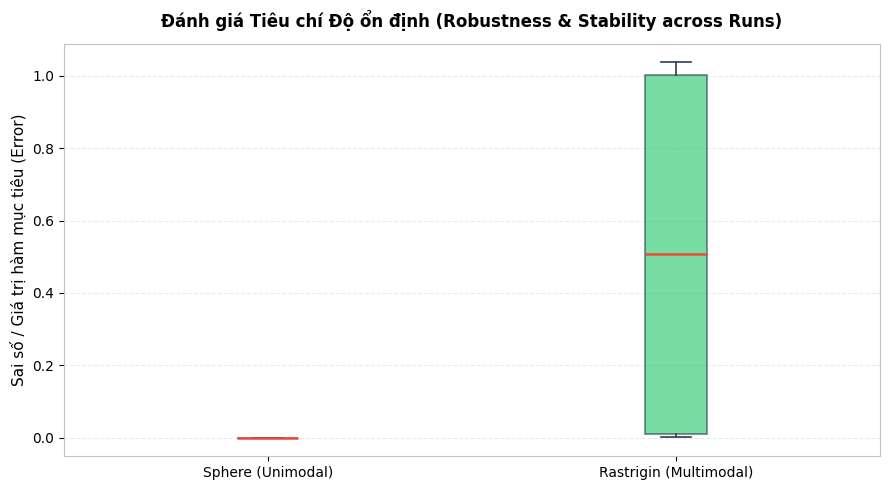

,Criterion (Tiêu chí),Value (Giá trị)
0,Best Fitness (Nghiệm tốt nhất),1.366261e-03
1,Mean Fitness (Trung bình),5.297160e-01
2,Worst Fitness (Kém nhất),1.037065e+00
3,Std Fitness (Độ lệch chuẩn - Tính ổn định),4.667471e-01
4,Mean Convergence Iter (Vòng lặp hội tụ TB),30.0
5,Final Diversity (Độ đa dạng cuối),0.4333
6,Mean Runtime (Thời gian chạy TB - giây),0.0014


In [10]:
n_seeds = 20
box_data = {"Sphere (Unimodal)": [], "Rastrigin (Multimodal)": []}
runs_rastrigin_all = []

for s in range(n_seeds):
    seed_val = s * 13 + 17
    # Sphere
    opt_sph = StandardPSO(
        fitness_func=bench_sphere['func'],
        dim=2,
        bounds=bench_sphere['bounds'],
        n_particles=20,
        max_iter=30,
        random_seed=seed_val
    )
    r_sph = opt_sph.optimize()
    box_data["Sphere (Unimodal)"].append(r_sph['gbest_val'])

    # Rastrigin
    opt_ras = StandardPSO(
        fitness_func=bench_rastrigin['func'],
        dim=2,
        bounds=bench_rastrigin['bounds'],
        n_particles=20,
        max_iter=30,
        random_seed=seed_val
    )
    r_ras = opt_ras.optimize()
    box_data["Rastrigin (Multimodal)"].append(r_ras['gbest_val'])
    runs_rastrigin_all.append(r_ras)

# Vẽ biểu đồ Boxplot độ ổn định
fig_box = plot_robustness_boxplots(box_data)
plt.show()

# Bảng tổng hợp thống kê tiêu chí qua 20 lần chạy
summary_stats = aggregate_experiment_metrics(runs_rastrigin_all, optimum=0.0)
summary_stats


---
## 7. Tiêu chí 6: Đánh giá Thực nghiệm trên Bài toán Tinh chỉnh Siêu tham số Mạng Nơ-ron (MLP)
Trong dự án này, Standard PSO được áp dụng để tìm kiếm bộ 3 siêu tham số của mạng MLP:
* $n_{neurons} \in [16, 256]$ (Số nơ-ron lớp ẩn)
* $\text{learning rate } (lr) \in [10^{-4}, 10^{-1}]$ (Tốc độ học)
* $\text{regularization } (\alpha) \in [10^{-5}, 10^{-1}]$ (Hệ số điều chuẩn L2)

Dưới đây là so sánh kết quả thực nghiệm của Standard PSO trên hai bộ dữ liệu thực tế: **Bank Marketing** và **Forest Covertype**:


In [11]:
# Dữ liệu thực nghiệm thu được từ quá trình huấn luyện thực tế
real_results = [
    {
        'Dataset': 'Bank Marketing',
        'Algorithm': 'Standard PSO',
        'Test_Accuracy': 0.8518,
        'CV_Score': 0.8486,
        'n_neurons': 214,
        'learning_rate': 0.01053,
        'alpha': 0.00016,
        'n_layers': 2,
        'batch_size': 200,
        'Swarm_Config': 'N=12, T=20, w=0.7, c1=1.5, c2=1.5'
    },
    {
        'Dataset': 'Forest Covertype',
        'Algorithm': 'Standard PSO',
        'Test_Accuracy': 0.8507,
        'CV_Score': 0.8409,
        'n_neurons': 229,
        'learning_rate': 0.00199,
        'alpha': 0.00172,
        'n_layers': 2,
        'batch_size': 200,
        'Swarm_Config': 'N=12, T=20, w=0.7, c1=1.5, c2=1.5'
    }
]

df_real = pd.DataFrame(real_results)
df_real


,Dataset,Algorithm,Test_Accuracy,CV_Score,n_neurons,learning_rate,alpha,n_layers,batch_size,Swarm_Config
0,Bank Marketing,Standard PSO,0.8518,0.8486,214,0.01053,0.00016,2,200,"N=12, T=20, w=0.7, c1=1.5, c2=1.5"
1,Forest Covertype,Standard PSO,0.8507,0.8409,229,0.00199,0.00172,2,200,"N=12, T=20, w=0.7, c1=1.5, c2=1.5"


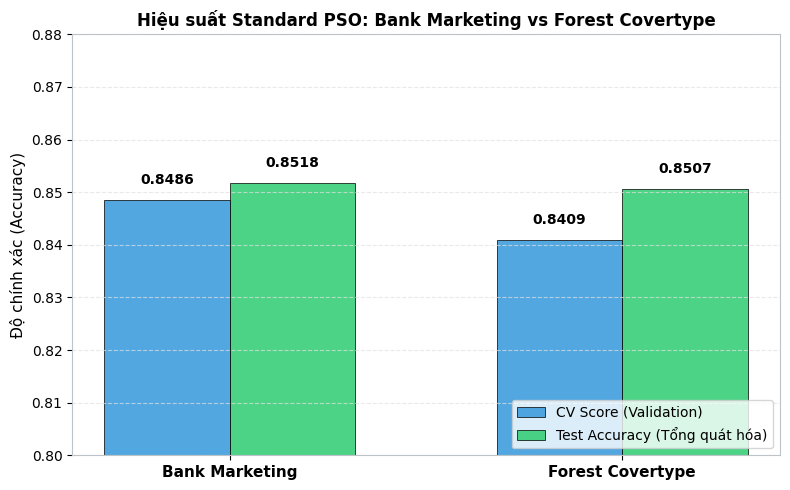

In [12]:
# Biểu đồ cột so sánh Test Accuracy và CV Score
fig, ax_bar = plt.subplots(figsize=(8, 5))
datasets = df_real['Dataset']
x_pos = np.arange(len(datasets))
width = 0.32

ax_bar.bar(x_pos - width/2, df_real['CV_Score'], width, label='CV Score (Validation)', 
           color=PALETTE['primary'], alpha=0.85, edgecolor='black', lw=0.6)
ax_bar.bar(x_pos + width/2, df_real['Test_Accuracy'], width, label='Test Accuracy (Tổng quát hóa)', 
           color=PALETTE['secondary'], alpha=0.85, edgecolor='black', lw=0.6)

for i in range(len(datasets)):
    ax_bar.text(x_pos[i] - width/2, df_real['CV_Score'][i] + 0.003, f"{df_real['CV_Score'][i]:.4f}", 
                ha='center', fontsize=10, fontweight='bold')
    ax_bar.text(x_pos[i] + width/2, df_real['Test_Accuracy'][i] + 0.003, f"{df_real['Test_Accuracy'][i]:.4f}", 
                ha='center', fontsize=10, fontweight='bold')

ax_bar.set_xticks(x_pos)
ax_bar.set_xticklabels(datasets, fontsize=11, fontweight='bold')
ax_bar.set_ylim(0.80, 0.88)
ax_bar.set_ylabel('Độ chính xác (Accuracy)', fontsize=11)
ax_bar.set_title('Hiệu suất Standard PSO: Bank Marketing vs Forest Covertype', fontsize=12, fontweight='bold')
ax_bar.grid(True, axis='y', linestyle='--', alpha=0.7)
ax_bar.legend(loc='lower right', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


---
## 8. Biểu đồ Phân tán Hạt (Particle Distribution Scatter Plot) của Standard PSO trên 2 Bộ Dữ liệu

Dưới đây là biểu đồ phân tán vị trí các hạt của **Standard PSO** được nạp trực tiếp từ checkpoint thực nghiệm của cả 2 bộ dữ liệu:
* `bank_marketing/results/checkpoints/standard_pso.pkl`
* `covertype/results/checkpoints/standard_pso.pkl`

### Quy cách định dạng:
1. **Tỉ lệ khung hình vuông (Square Aspect Ratio 1:1)**: Đảm bảo khoảng cách giữa các chiều tham số trực quan và cân đối.
2. **Dải màu pastel nhẹ nhàng (Soft RdYlGn / YlGnBu)**: Điểm số `CV Accuracy` được tự động căn chỉnh khoảng giá trị để màu sắc chuyển tiếp mượt mà, viền xám nhẹ thanh lịch.
3. **Đánh dấu nghiệm tối ưu ($G_{best}$)**: Ngôi sao đỏ nổi bật viền đen kèm thông số chi tiết ($N_{neurons}$, $lr$, $CV$).


Nạp Checkpoint Bank Marketing: True (d:\Code\JupyterNotebook\bank_marketing\results\checkpoints\standard_pso.pkl)
Nạp Checkpoint Forest Covertype: True (d:\Code\JupyterNotebook\covertype\results\checkpoints\standard_pso.pkl)


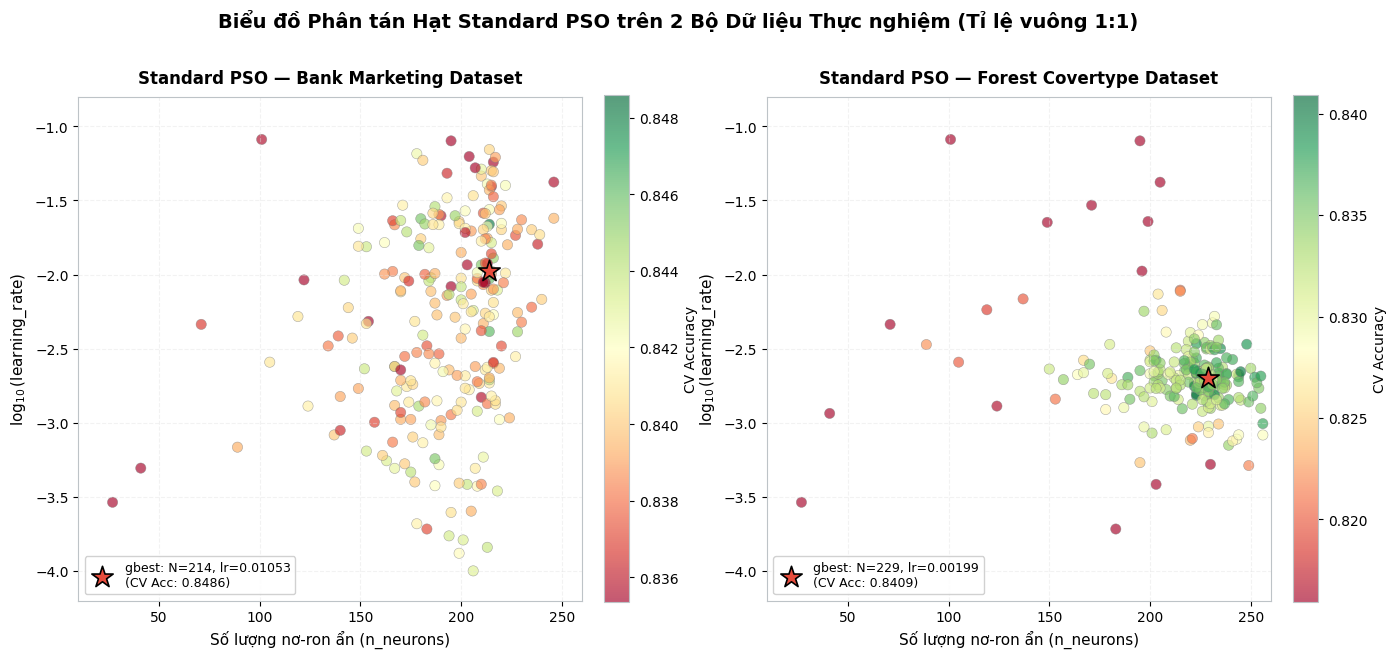

In [13]:
# Nạp trực tiếp kết quả checkpoint của Standard PSO từ 2 bài toán
bank_ckpt_path = os.path.join(WORKSPACE_ROOT, 'bank_marketing', 'results', 'checkpoints', 'standard_pso.pkl')
cover_ckpt_path = os.path.join(WORKSPACE_ROOT, 'covertype', 'results', 'checkpoints', 'standard_pso.pkl')

if not os.path.exists(bank_ckpt_path):
    bank_ckpt_path = os.path.abspath('../../bank_marketing/results/checkpoints/standard_pso.pkl')
if not os.path.exists(cover_ckpt_path):
    cover_ckpt_path = os.path.abspath('../../covertype/results/checkpoints/standard_pso.pkl')

print(f"Nạp Checkpoint Bank Marketing: {os.path.exists(bank_ckpt_path)} ({bank_ckpt_path})")
print(f"Nạp Checkpoint Forest Covertype: {os.path.exists(cover_ckpt_path)} ({cover_ckpt_path})")

b_ckpt = joblib.load(bank_ckpt_path)
c_ckpt = joblib.load(cover_ckpt_path)

hist_bank = b_ckpt['history']
hist_cover = c_ckpt['history']

fig = plt.figure(figsize=(16, 7))
gs = gridspec.GridSpec(1, 2, figure=fig, wspace=0.25)

def plot_dataset_scatter(ax, hist, dataset_name):
    scores = hist['score']
    vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
    vmax = float(scores.max())
    
    sc = ax.scatter(
        hist['n_neurons'], np.log10(hist['lr']),
        c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
        alpha=0.65, s=55, edgecolors='grey', lw=0.4
    )
    cbar = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('CV Accuracy', fontsize=10)

    best_row = hist.loc[hist['score'].idxmax()]
    n_best = int(best_row['n_neurons'])
    lr_best = best_row['lr']
    cv_best = best_row['score']

    ax.scatter(
        n_best, np.log10(lr_best), c='#e74c3c', s=260, marker='*',
        edgecolors='black', lw=1.2, zorder=6,
        label=f"gbest: N={n_best}, lr={lr_best:.5f}\n(CV Acc: {cv_best:.4f})"
    )

    ax.set_box_aspect(1)
    ax.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
    ax.set_ylabel(r'$\log_{10}(\mathrm{learning\_rate})$', fontsize=11)
    ax.set_title(f'Standard PSO — {dataset_name}', fontsize=12, fontweight='bold', pad=10)
    ax.set_xlim(10, 260)
    ax.set_ylim(-4.2, -0.8)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='lower left', fontsize=9, framealpha=0.9)

plot_dataset_scatter(fig.add_subplot(gs[0, 0]), hist_bank, 'Bank Marketing Dataset')
plot_dataset_scatter(fig.add_subplot(gs[0, 1]), hist_cover, 'Forest Covertype Dataset')

fig.suptitle('Biểu đồ Phân tán Hạt Standard PSO trên 2 Bộ Dữ liệu Thực nghiệm (Tỉ lệ vuông 1:1)', 
             fontsize=14, fontweight='bold', y=0.98)
plt.show()


### Phân tích Không gian Tham số Chiều thứ 3: Hệ số Điều chuẩn L2 ($\log_{10}(\alpha)$)
Để quan sát đầy đủ không gian siêu tham số 3 chiều $(n_{neurons}, lr, \alpha)$, dưới đây là lát cắt phân tán thứ 2 giữa **Số nơ-ron** và **Hệ số điều chuẩn L2 ($\alpha$)**:


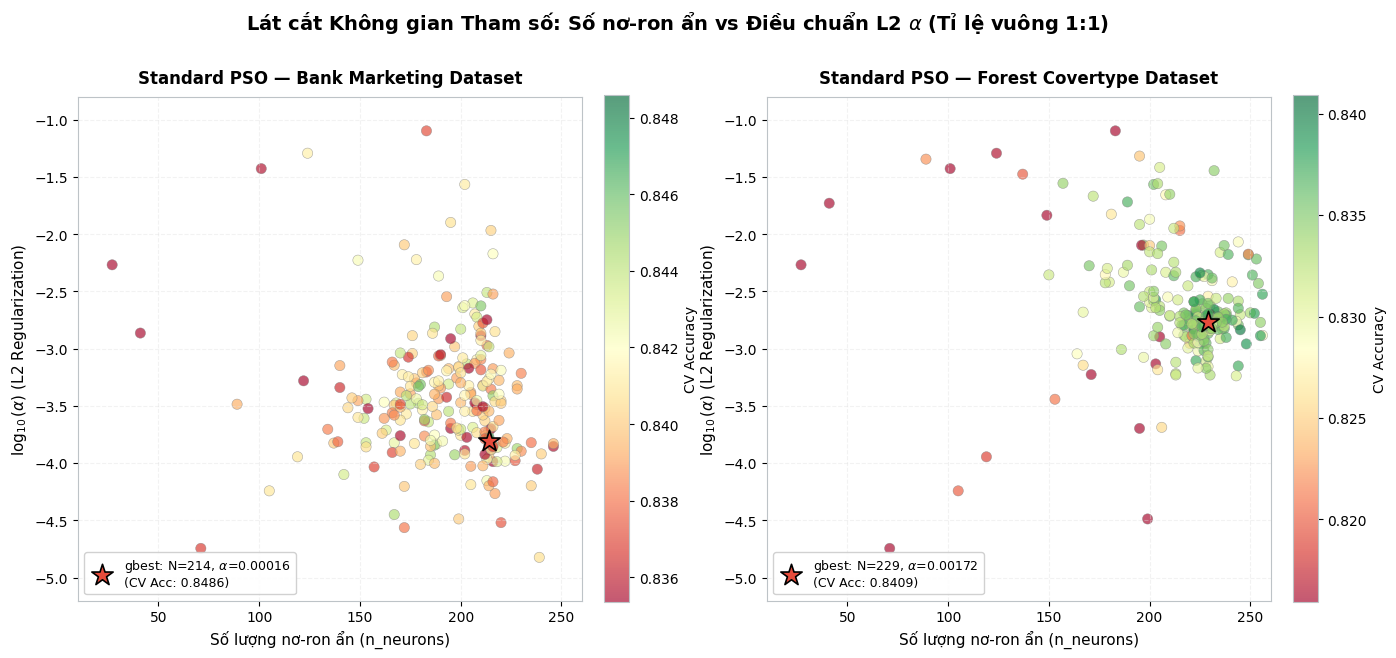

In [14]:
fig = plt.figure(figsize=(16, 7))
gs = gridspec.GridSpec(1, 2, figure=fig, wspace=0.25)

def plot_alpha_scatter(ax, hist, dataset_name):
    scores = hist['score']
    vmin = max(float(np.percentile(scores, 5)), float(scores.max() - 0.025))
    vmax = float(scores.max())
    
    sc = ax.scatter(
        hist['n_neurons'], np.log10(hist['alpha']),
        c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
        alpha=0.65, s=55, edgecolors='grey', lw=0.4
    )
    cbar = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('CV Accuracy', fontsize=10)

    best_row = hist.loc[hist['score'].idxmax()]
    n_best = int(best_row['n_neurons'])
    alpha_best = best_row['alpha']
    cv_best = best_row['score']

    ax.scatter(
        n_best, np.log10(alpha_best), c='#e74c3c', s=260, marker='*',
        edgecolors='black', lw=1.2, zorder=6,
        label=f"gbest: N={n_best}, $\\alpha$={alpha_best:.5f}\n(CV Acc: {cv_best:.4f})"
    )

    ax.set_box_aspect(1)
    ax.set_xlabel('Số lượng nơ-ron ẩn (n_neurons)', fontsize=11)
    ax.set_ylabel(r'$\log_{10}(\alpha)$ (L2 Regularization)', fontsize=11)
    ax.set_title(f'Standard PSO — {dataset_name}', fontsize=12, fontweight='bold', pad=10)
    ax.set_xlim(10, 260)
    ax.set_ylim(-5.2, -0.8)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='lower left', fontsize=9, framealpha=0.9)

plot_alpha_scatter(fig.add_subplot(gs[0, 0]), hist_bank, 'Bank Marketing Dataset')
plot_alpha_scatter(fig.add_subplot(gs[0, 1]), hist_cover, 'Forest Covertype Dataset')

fig.suptitle('Lát cắt Không gian Tham số: Số nơ-ron ẩn vs Điều chuẩn L2 $\\alpha$ (Tỉ lệ vuông 1:1)', 
             fontsize=14, fontweight='bold', y=0.98)
plt.show()


---
### Đối sánh Đường cong Hội tụ Thực tế giữa Bank Marketing và Forest Covertype


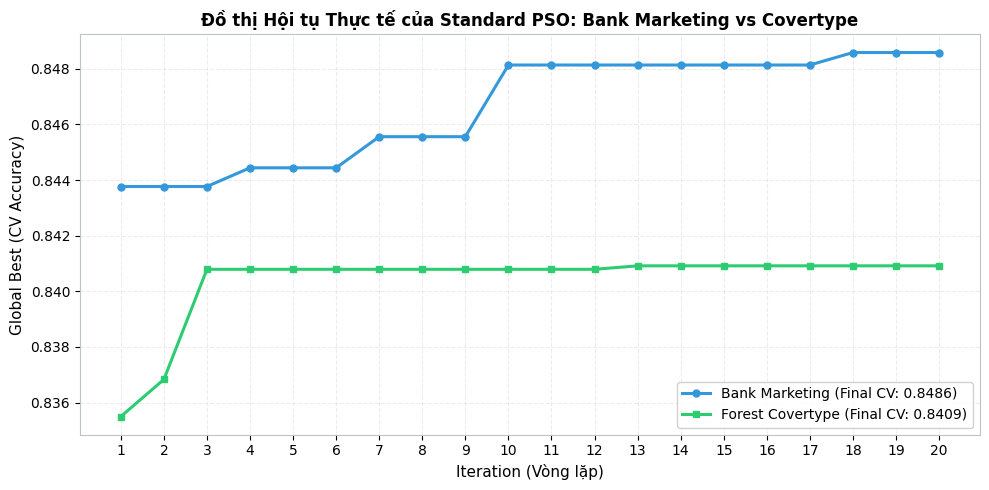

In [15]:
conv_bank = b_ckpt['convergence']
conv_cover = c_ckpt['convergence']
iters = range(1, len(conv_bank) + 1)

fig, ax_conv = plt.subplots(figsize=(10, 5))
ax_conv.plot(iters, conv_bank, marker='o', markersize=5, lw=2.2, color=PALETTE['primary'],
             label=f"Bank Marketing (Final CV: {conv_bank[-1]:.4f})")
ax_conv.plot(iters, conv_cover, marker='s', markersize=5, lw=2.2, color=PALETTE['secondary'],
             label=f"Forest Covertype (Final CV: {conv_cover[-1]:.4f})")

ax_conv.set_xlabel('Iteration (Vòng lặp)', fontsize=11)
ax_conv.set_ylabel('Global Best (CV Accuracy)', fontsize=11)
ax_conv.set_title('Đồ thị Hội tụ Thực tế của Standard PSO: Bank Marketing vs Covertype', fontsize=12, fontweight='bold')
ax_conv.set_xticks(list(iters))
ax_conv.grid(True, linestyle='--', alpha=0.6)
ax_conv.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()


---
## 9. Kết luận & Tổng hợp Đánh giá Tiêu chí Standard PSO

| Tiêu chí Đánh giá | Đặc điểm của Standard PSO | Ưu điểm | Nhược điểm / Hạn chế |
| :--- | :--- | :--- | :--- |
| **1. Tốc độ Hội tụ (Convergence)** | Hội tụ tương đối nhanh trên hàm đơn giản nhờ cơ chế hút kép ($P_{best}$ & $G_{best}$). | Dễ triển khai, chi phí tính toán mỗi vòng lặp thấp. | Tốc độ suy giảm mạnh khi rơi vào thung lũng phẳng. |
| **2. Độ đa dạng Quần thể (Diversity)** | Độ đa dạng suy giảm rất nhanh do các hạt bị kéo tập trung về $G_{best}$. | Tập trung khai thác tốt ở vùng lân cận nghiệm tốt. | Thiếu cơ chế duy trì đa dạng, dễ bị sa lầy cực tiểu địa phương (**Premature Convergence**). |
| **3. Động học Vận tốc (Velocity)** | Vận tốc phụ thuộc lớn vào việc kẹp $V_{max}$. | Kiểm soát được biên độ di chuyển. | Nếu $V_{max}$ quá lớn $\rightarrow$ bùng nổ vận tốc; nếu quá nhỏ $\rightarrow$ chuyển động chậm chạp. |
| **4. Độ nhạy Tham số (Sensitivity)** | Rất nhạy cảm với bộ 3 thông số $(w, c_1, c_2)$. | $w=0.7, c_1=c_2=1.5$ là điểm cân bằng tương đối tốt. | Trọng số $w$ cố định không thể linh hoạt chuyển từ khám phá sang khai thác. |
| **5. Độ bền vững (Robustness)** | Độ lệch chuẩn (Std) tương đối lớn trên hàm đa đỉnh (Rastrigin). | Kết quả tốt khi hàm đơn đỉnh (Sphere). | Cần chạy nhiều hạt ($N$) hoặc nhiều lần để tránh nghiệm cục bộ xấu. |
| **6. Phân bố Hạt trên 2 Bộ Dữ liệu** | Bầy đàn hội tụ về vùng $N_{neurons} \in [210, 230]$ ở cả 2 tập. | Tìm ra kiến trúc mạng MLP 2 lớp ẩn phù hợp trên cả 2 bài toán. | Hạt có xu hướng co cụm sớm vào vùng lân cận điểm khởi tạo tốt ban đầu. |

> **Nhận xét chuyên sâu về Biểu đồ Phân tán:**
> * Trên **Bank Marketing**, các hạt có điểm số cao (màu xanh lá) tập trung rõ rệt ở dải learning rate cao hơn ($\sim 10^{-2}$), với nghiệm tốt nhất đạt tại $N=214, lr=0.01053, \alpha=0.00016$.
> * Trên **Forest Covertype**, bầy đàn tìm ra vùng tối ưu ở learning rate thấp hơn ($\sim 2 \times 10^{-3}$), với $N=229, lr=0.00199, \alpha=0.00172$. Lý do là Covertype có số lượng chiều đặc trưng và số mẫu lớn hơn, đòi hỏi bước cập nhật gradient nhỏ và thận trọng hơn để tránh phân kỳ.
> * Cả hai bộ dữ liệu đều chứng minh Standard PSO có khả năng định hướng đàn hạt vào khu vực có độ chính xác cao, nhưng các hạt còn lại nhanh chóng bị mất độ đa dạng và co cụm quanh $G_{best}$ — đây chính là động lực để sử dụng các biến thể cải tiến như **Linear Decay PSO, CPSO, FO-PSO** nhằm duy trì khả năng khám phá lâu hơn.
